In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

In [2]:
X,y = make_classification(n_samples=1000,n_features=10,n_informative=6,random_state=42)
print(pd.DataFrame(X).describe().T.head())
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

    count      mean       std       min       25%       50%       75%  \
0  1000.0 -1.012153  1.240373 -5.129490 -1.804212 -1.029265 -0.246030   
1  1000.0  0.532850  1.594241 -5.446468 -0.534844  0.553832  1.622359   
2  1000.0 -0.076207  1.826369 -5.522664 -1.408453 -0.064367  1.200760   
3  1000.0 -0.013345  1.022652 -3.688365 -0.704614 -0.030525  0.686883   
4  1000.0 -0.394057  1.825996 -7.844223 -1.579088 -0.452602  0.812573   

        max  
0  3.218202  
1  5.806373  
2  5.526213  
3  3.529055  
4  5.466089  


                    Model  Test Acc  CV Mean    CV Std
0  Decision Tree (single)     0.820    0.842  0.031875
1                 Bagging     0.865    0.899  0.010677
2           Random Forest     0.850    0.899  0.015620
3                AdaBoost     0.735    0.815  0.013784
4       Gradient Boosting     0.835    0.877  0.016000


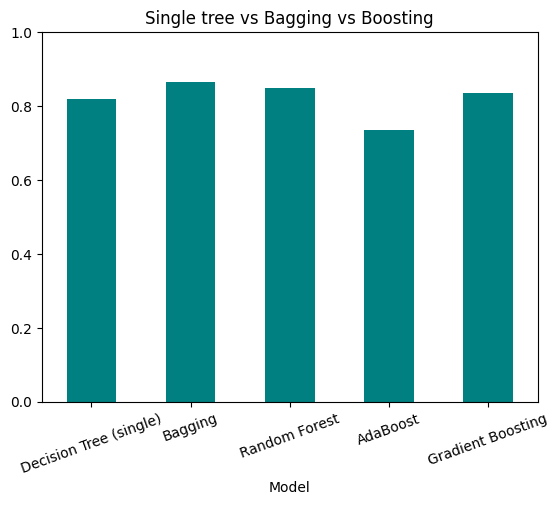

In [3]:
models = {"Decision Tree (single)":DecisionTreeClassifier(random_state=42),
          "Bagging":BaggingClassifier(estimator=DecisionTreeClassifier(),n_estimators=50,random_state=42),
          "Random Forest":RandomForestClassifier(n_estimators=50,random_state=42),
          "AdaBoost":AdaBoostClassifier(n_estimators=50,random_state=42),
          "Gradient Boosting":GradientBoostingClassifier(n_estimators=50,random_state=42)}
rows = []
for name,m in models.items():
    acc = accuracy_score(y_test, m.fit(X_train,y_train).predict(X_test))
    cv = cross_val_score(m,X,y,cv=5)                                  # shows stability (variance)
    rows.append([name,acc,cv.mean(),cv.std()])
res = pd.DataFrame(rows,columns=["Model","Test Acc","CV Mean","CV Std"]); print(res)
res.set_index("Model")["Test Acc"].plot(kind="bar",ylim=(0,1),color="teal"); plt.xticks(rotation=20); plt.title("Single tree vs Bagging vs Boosting"); plt.show()